# PII Redaction Evaluation

This notebook explains the evaluation results saved in this repository, and lets you run the same checks on **your own data** and **your own redaction system**.

It has three parts:

1. **How to read the scores**: what is measured, in plain English.
2. **The published results**: charts and tables drawn from the saved result files in `results/`. Nothing is re-evaluated here; the runs behind those files took hours.
3. **Your system**: two cells you can change (your detector, your data), then the same scoring and the same style of breakdown, next to some of our detectors.

## 1. How to read the scores

A **detector** reads text and says "these stretches are personal information", such as a name, a place or a date. To grade one, we compare its answers with a human-marked answer key.

- **Precision**: of everything the detector flagged, how much really was personal information. Low precision means lots of harmless text gets masked.
- **Recall**: of everything that really was personal information, how much the detector found. Low recall means personal information leaks through.
- **F2**: one number that combines the two, counting recall twice as heavily as precision. We use it because a missed name is worse than an over-masked word. A score of 1.0 is perfect and 0.0 is useless.

There are two ways to decide whether a flag "matches" an answer:

- **Strict**: the detector must mark exactly the same stretch of text, from the same first character to the same last one, with the same kind of information. Flagging "Maria" when the key says "Maria Lindqvist" is a miss.
- **Relaxed**: the flag must overlap an answer of the same kind by at least half of the longer of the two. Flagging "Maria Lindqvist" when the key says "Ms. Maria Lindqvist" matches; flagging "Maria" when the key says "Maria Lindqvist" still does not, because it covers too little.

If the key marks overlapping stretches of the same kind (for example "Maria Lindqvist" and "Maria"), they count as one answer, and a flag that matches either of them gets the credit.

The gap between the two tells you how often a detector finds the right thing but cuts it short or runs it long. For redaction that matters: a half-masked name still leaks.

Every dataset and detector uses its own labels, so they are all translated onto six common kinds: person, organization, location, date or time, quantity (amounts of money and similar), and identifier (emails, phone numbers, ID codes and the like).

Two rules decide which kinds count in a score. A dataset only marks some kinds (TAB all six; MAPA and Worldwide all except identifiers), so a flag of a kind the dataset never marks is not counted as a false alarm. And a detector is charged for misses only on the kinds it looks for. Detectors are therefore graded on different sets of kinds: the scores show how good each one is at what it attempts, not which one covers more.

In [1]:
import os
import warnings
from pathlib import Path

# Quiet the model libraries' progress bars and deprecation chatter so the saved output shows only results.
os.environ.setdefault("TQDM_DISABLE", "1")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pii_toolbox.core import DatasetSplit, PiiType
from pii_toolbox.evaluation.results_io import read_record
from pii_toolbox.evaluation.tables import english_runs, load_cost_results, load_records

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# The notebook may be started from the repository root or from notebooks/.
REPO = next(folder for folder in (Path.cwd(), *Path.cwd().parents) if (folder / "pyproject.toml").exists())
RESULTS = REPO / "results"

DATASET_NAMES = {"tab": "TAB", "mapa": "MAPA (English)", "worldwide": "Worldwide English"}
TYPES = list(PiiType)
TYPE_NAMES = {t: t.value.replace("_", " ").title() for t in TYPES}

# Colour-blind-safe palette, one fixed colour per detector so charts can be read across.
TOOL_COLORS = {
    "spacy_lg": "#0072B2",
    "spacy_sm": "#56B4E9",
    "roberta": "#D55E00",
    "gliner": "#009E73",
    "presidio_structured": "#7F7F7F",
}
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

## 2. The published results

Everything in this part is read from the saved files in `results/test` (accuracy) and `results/cost` (speed and memory). All scores are on each dataset's **test** split.

Three public datasets were used:

- **TAB**: English court judgments, annotated for personal information by several people.
- **MAPA**: legal text in many languages; we score English, French and German.
- **Worldwide English**: English newswire articles.

Five detectors were measured on their own: `spacy_lg` and `spacy_sm` (two sizes of a general language-analysis library), `roberta` (a large neural name finder), `gliner` (a neural model for personal information that also reads French and German), and `presidio_structured` (rules for things with a fixed shape such as emails and card numbers). Each was also measured joined with `presidio_structured`. Those joined versions score close to the model alone on MAPA and Worldwide; on TAB they score up to about 0.05 lower for `roberta`, `spacy_lg` and `spacy_sm` (for example strict F2 0.373 for `roberta` against 0.344 with `presidio_structured`), because the joined setup is also graded on identifiers, which the rules mostly miss. The charts below show the five single detectors.

In [2]:
records_off = load_records(RESULTS / "test", DatasetSplit.TEST, coreference=False)
records_on = load_records(RESULTS / "test", DatasetSplit.TEST, coreference=True)
runs_off = english_runs(records_off)
runs_on = english_runs(records_on)
costs = {row["setup"]: row for row in load_cost_results(RESULTS / "cost")}

TOOLS = ["spacy_lg", "spacy_sm", "roberta", "gliner", "presidio_structured"]
DATASETS = list(DATASET_NAMES)


def report(runs, tool, dataset, strict=True):
    run = runs[(tool, dataset)]
    return run.exact_boundaries if strict else run.any_overlap


def overall_table(strict):
    rows = {
        DATASET_NAMES[ds]: {
            tool: report(runs_off, tool, ds, strict).overall_micro.f2 for tool in TOOLS
        }
        for ds in DATASETS
    }
    return pd.DataFrame(rows).T.round(3)


print(f"{len(records_off)} runs without co-reference, {len(records_on)} with, {len(costs)} cost files")

45 runs without co-reference, 27 with, 9 cost files


### Which tool is best on each dataset?

Overall F2 with strict matching. Taller is better. Each detector is graded only on the kinds it looks for, so a high bar means it is good at what it attempts, not that it covers more.

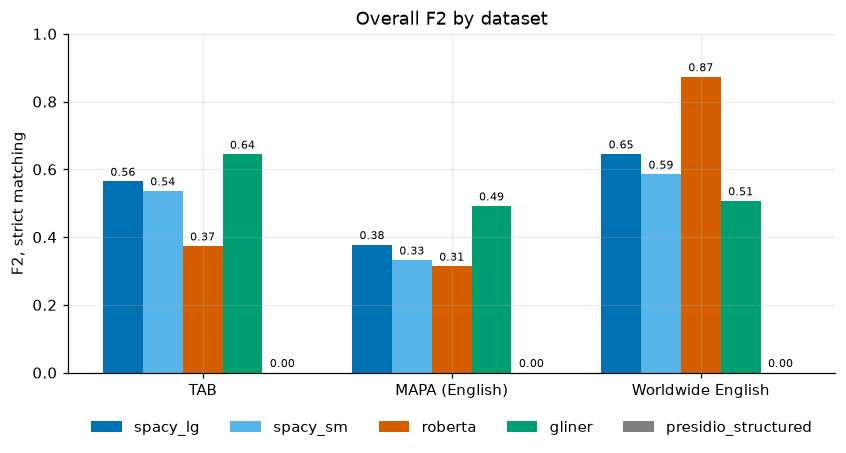

,spacy_lg,spacy_sm,roberta,gliner,presidio_structured
TAB,0.564,0.536,0.373,0.644,0.0
MAPA (English),0.378,0.332,0.314,0.492,0.0
Worldwide English,0.645,0.585,0.873,0.507,0.0


In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
width = 0.16
for i, tool in enumerate(TOOLS):
    values = [report(runs_off, tool, ds).overall_micro.f2 for ds in DATASETS]
    bars = ax.bar(np.arange(len(DATASETS)) + (i - 2) * width, values, width, label=tool, color=TOOL_COLORS[tool])
    ax.bar_label(bars, fmt="%.2f", fontsize=7, padding=2)
ax.set_xticks(range(len(DATASETS)), [DATASET_NAMES[d] for d in DATASETS])
ax.set_ylabel("F2, strict matching")
ax.set_ylim(0, 1)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
ax.set_title("Overall F2 by dataset")
plt.show()

best = overall_table(strict=True).idxmax(axis=1)
overall_table(strict=True)

### Missing more than flagging wrongly

Each dot is one detector. Further right is higher precision (fewer false alarms), further up is higher recall (fewer leaks). The curves are lines of equal F2, so a dot beyond a curve scores better than that level. Because F2 values recall more, a dot high on the chart is rewarded over one far to the right.

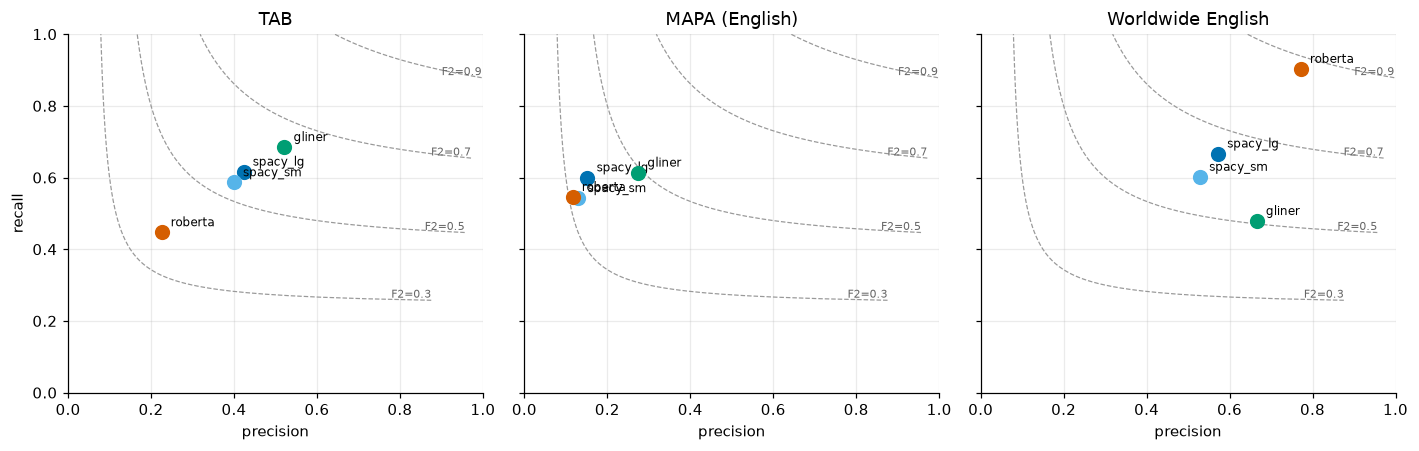

,TAB,MAPA (English),Worldwide English
spacy_lg,P 0.42 / R 0.62,P 0.15 / R 0.60,P 0.57 / R 0.67
spacy_sm,P 0.40 / R 0.59,P 0.13 / R 0.54,P 0.53 / R 0.60
roberta,P 0.23 / R 0.45,P 0.12 / R 0.55,P 0.77 / R 0.90
gliner,P 0.52 / R 0.68,P 0.27 / R 0.61,P 0.67 / R 0.48


In [4]:
def f2_curve(level):
    recall = np.linspace(level / 2 + 0.001, 1, 200)
    precision = level * recall / (5 * recall - 4 * level)
    keep = (precision > 0) & (precision <= 1)
    return precision[keep], recall[keep]


fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, ds in zip(axes, DATASETS):
    for level in (0.3, 0.5, 0.7, 0.9):
        p, r = f2_curve(level)
        ax.plot(p, r, color="#999", lw=0.8, ls="--")
        ax.text(p[0], r[0], f"F2={level}", fontsize=7, color="#666", ha="right", va="bottom")
    for tool in TOOLS[:-1]:
        score = report(runs_off, tool, ds).overall_micro
        ax.scatter(score.precision, score.recall, s=80, color=TOOL_COLORS[tool], zorder=3)
        ax.annotate(tool, (score.precision, score.recall), textcoords="offset points", xytext=(6, 4), fontsize=8)
    ax.set_title(DATASET_NAMES[ds])
    ax.set_xlabel("precision")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
axes[0].set_ylabel("recall")
plt.tight_layout()
plt.show()

pd.DataFrame(
    {
        DATASET_NAMES[ds]: {
            tool: (report(runs_off, tool, ds).overall_micro.precision, report(runs_off, tool, ds).overall_micro.recall)
            for tool in TOOLS[:-1]
        }
        for ds in DATASETS
    }
).map(lambda pr: f"P {pr[0]:.2f} / R {pr[1]:.2f}")

### Strict against relaxed: right thing, wrong edges

For each detector, the dark bar is strict matching (exact edges) and the light bar is relaxed matching (any overlap). The gap is the share of results where the detector found the right thing but the edges were off.

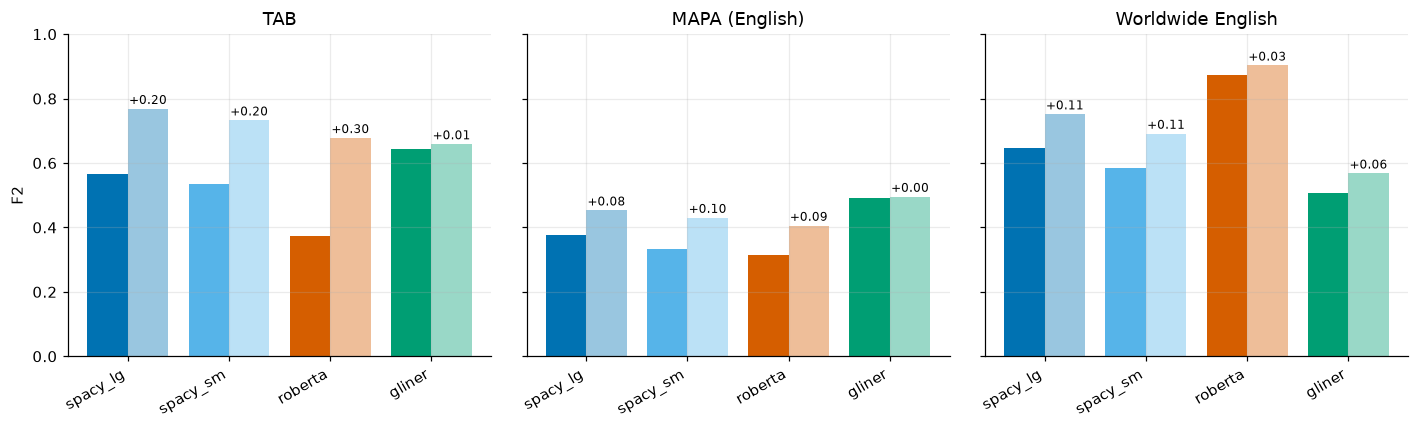

,spacy_lg,spacy_sm,roberta,gliner,presidio_structured
relaxed minus strict,,,,,
TAB,0.204,0.196,0.305,0.015,0.011
MAPA (English),0.075,0.098,0.091,0.003,0.000
Worldwide English,0.106,0.106,0.030,0.061,0.000


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, ds in zip(axes, DATASETS):
    x = np.arange(len(TOOLS[:-1]))
    strict = [report(runs_off, t, ds, True).overall_micro.f2 for t in TOOLS[:-1]]
    relaxed = [report(runs_off, t, ds, False).overall_micro.f2 for t in TOOLS[:-1]]
    colors = [TOOL_COLORS[t] for t in TOOLS[:-1]]
    ax.bar(x - 0.2, strict, 0.4, color=colors, label="strict")
    ax.bar(x + 0.2, relaxed, 0.4, color=colors, alpha=0.4, label="relaxed")
    for xi, s, r in zip(x, strict, relaxed):
        ax.text(xi + 0.2, r + 0.015, f"+{r - s:.2f}", ha="center", fontsize=8)
    ax.set_xticks(x, TOOLS[:-1], rotation=30, ha="right")
    ax.set_title(DATASET_NAMES[ds])
axes[0].set_ylabel("F2")
axes[0].set_ylim(0, 1)
plt.tight_layout()
plt.show()

(overall_table(strict=False) - overall_table(strict=True)).round(3).rename_axis("relaxed minus strict")

### Does resolving repeated names help?

"Co-reference" means: if the detector found "Maria Lindqvist" and the text later says just "Ms. Lindqvist", mark the later mention too. The bars show how much F2 changes when this is switched on (English text, strict matching). Bars to the right of zero are improvements.

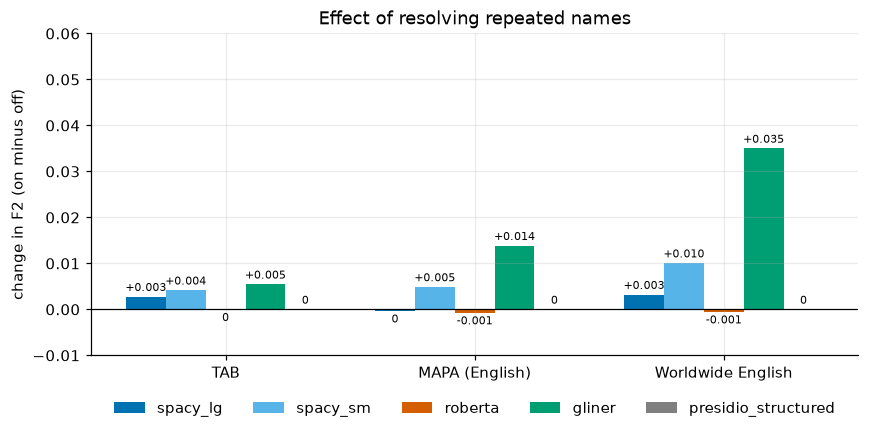

,TAB,MAPA (English),Worldwide English
spacy_lg,0.564 -> 0.567,0.378 -> 0.377,0.645 -> 0.648
spacy_sm,0.536 -> 0.540,0.332 -> 0.337,0.585 -> 0.596
roberta,0.373 -> 0.373,0.314 -> 0.313,0.873 -> 0.872
gliner,0.644 -> 0.650,0.492 -> 0.506,0.507 -> 0.542
presidio_structured,0.000 -> 0.000,0.000 -> 0.000,0.000 -> 0.000


In [6]:
fig, ax = plt.subplots(figsize=(9, 3.8))
width = 0.16
for i, tool in enumerate(TOOLS):
    changes = [
        report(runs_on, tool, ds).overall_micro.f2 - report(runs_off, tool, ds).overall_micro.f2 for ds in DATASETS
    ]
    bars = ax.bar(np.arange(len(DATASETS)) + (i - 2) * width, changes, width, color=TOOL_COLORS[tool], label=tool)
    ax.bar_label(bars, labels=["0" if abs(v) < 0.0005 else f"{v:+.3f}" for v in changes], fontsize=7, padding=2)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(len(DATASETS)), [DATASET_NAMES[d] for d in DATASETS])
ax.set_ylabel("change in F2 (on minus off)")
ax.set_ylim(-0.01, 0.06)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
ax.set_title("Effect of resolving repeated names")
plt.show()

pd.DataFrame(
    {
        DATASET_NAMES[ds]: {
            tool: (report(runs_off, tool, ds).overall_micro.f2, report(runs_on, tool, ds).overall_micro.f2)
            for tool in TOOLS
        }
        for ds in DATASETS
    }
).map(lambda pair: f"{pair[0]:.3f} -> {pair[1]:.3f}")

### Scores by PII type

Strict F2 for each kind of information. Grey cells mean the detector cannot report that kind, or the dataset has none of it. Identifiers (emails, phone numbers, ID codes) are shown separately below: they are scored on TAB only, because MAPA and Worldwide do not mark them, and both Presidio's pattern matching and GLiNER can report them.

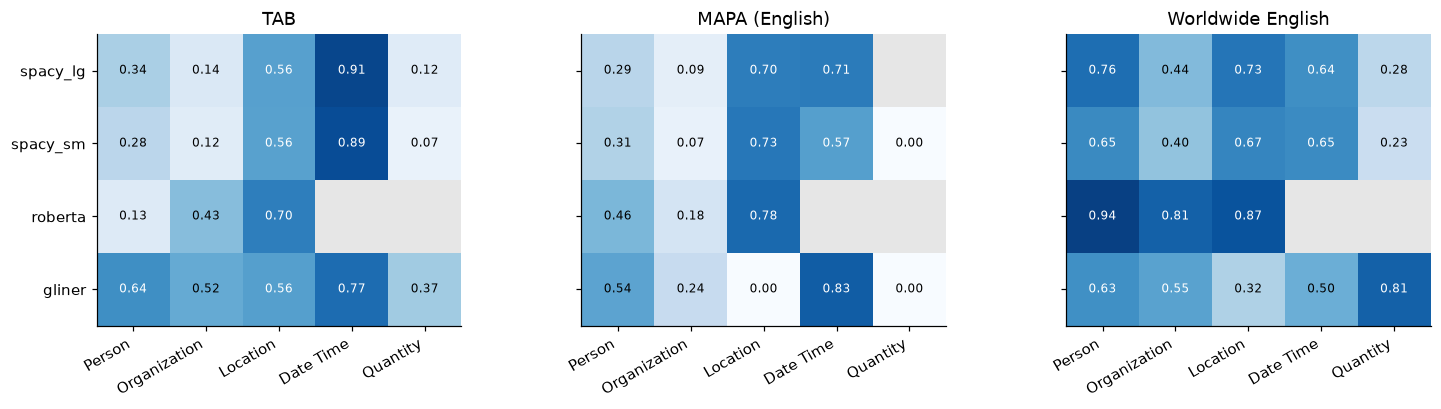

In [7]:
HEATMAP_TYPES = [t for t in TYPES if t is not PiiType.IDENTIFIER]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, ds in zip(axes, DATASETS):
    grid = np.full((len(TOOLS[:-1]), len(HEATMAP_TYPES)), np.nan)
    for i, tool in enumerate(TOOLS[:-1]):
        by_type = report(runs_off, tool, ds).by_type
        for j, t in enumerate(HEATMAP_TYPES):
            score = by_type.get(t)
            if score is not None:
                grid[i, j] = score.f2
    image = ax.imshow(np.ma.masked_invalid(grid), vmin=0, vmax=1, cmap="Blues")
    ax.set_facecolor("#e6e6e6")
    ax.grid(False)
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            if not np.isnan(grid[i, j]):
                ax.text(j, i, f"{grid[i, j]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if grid[i, j] > 0.55 else "black")
    ax.set_xticks(range(len(HEATMAP_TYPES)), [TYPE_NAMES[t] for t in HEATMAP_TYPES], rotation=30, ha="right")
    ax.set_yticks(range(len(TOOLS[:-1])), TOOLS[:-1])
    ax.set_title(DATASET_NAMES[ds])
plt.tight_layout()
plt.show()

#### Identifiers

Precision, recall and F2 for the identifier kind on TAB, with strict and relaxed matching. Only `gliner` and setups that include `presidio_structured` can report identifiers.


In [8]:
identifier_rows = {}
for (tool, dataset, language), record in sorted(records_off.items()):
    if dataset != "tab" or language != "en":
        continue
    strict = record.run.exact_boundaries.by_type.get(PiiType.IDENTIFIER)
    relaxed = record.run.any_overlap.by_type.get(PiiType.IDENTIFIER)
    if strict is None or relaxed is None:
        continue
    identifier_rows[tool.replace("+presidio_structured", "+rules")] = {
        ("strict", "precision"): strict.precision,
        ("strict", "recall"): strict.recall,
        ("strict", "F2"): strict.f2,
        ("relaxed", "precision"): relaxed.precision,
        ("relaxed", "recall"): relaxed.recall,
        ("relaxed", "F2"): relaxed.f2,
    }
pd.DataFrame(identifier_rows).T.round(3).rename_axis("identifiers on TAB")

strict                 relaxed              
                    precision recall     F2 precision recall     F2
identifiers on TAB                                                 
gliner                  0.922   0.45  0.501     0.940  0.459  0.511
gliner+rules            0.890   0.45  0.499     0.919  0.465  0.516
presidio_structured     0.000   0.00  0.000     0.375  0.009  0.011
roberta+rules           0.000   0.00  0.000     0.375  0.009  0.011
spacy_lg+rules          0.000   0.00  0.000     0.429  0.009  0.011
spacy_sm+rules          0.000   0.00  0.000     0.429  0.009  0.011

Identifiers are the weak spot for Presidio's rules and only partly covered by GLiNER. The rules alone get no identifier exactly right with strict matching, and with relaxed matching they find under 1% of them (recall 0.009), so they catch almost none of what TAB marks as an identifier. The few things they flag are often right (precision 0.375 to 0.429), but there are too few to matter. GLiNER, asked for case numbers and identification numbers, does much better: with strict matching its precision is 0.922 and recall 0.450 (F2 0.501), and with relaxed matching recall is 0.459 (F2 0.511), so it finds a little under half of them. Adding the rules to GLiNER changes little (strict F2 0.499, relaxed 0.516). `roberta` and the spaCy models cannot report identifiers on their own, so they are not in the table.

In [9]:
language_rows = {}
for tool in ["gliner", "roberta", "spacy_lg", "spacy_sm"]:
    row = {}
    for language in ("en", "fr", "de"):
        record = records_off.get((tool, "mapa", language))
        supported = record is not None and (record.languages is None or language in record.languages)
        row[language] = round(record.run.exact_boundaries.overall_micro.f2, 3) if supported else "not supported"
    language_rows[tool] = row
pd.DataFrame(language_rows).T.rename_axis("MAPA F2 (strict) by language")

,en,fr,de
MAPA F2 (strict) by language,,,
gliner,0.492,0.447,0.545
roberta,0.314,not supported,not supported
spacy_lg,0.378,not supported,not supported
spacy_sm,0.332,not supported,not supported


### Cost: what does the quality cost in time and memory?

Each dot is one detector on TAB. Further left is faster (time to process 1,000 characters, log scale), higher is better quality, and the dot's area grows with peak memory. Speed and memory were measured on a single machine (see `results/test/environment.json` and the cost files), so read them as relative sizes.

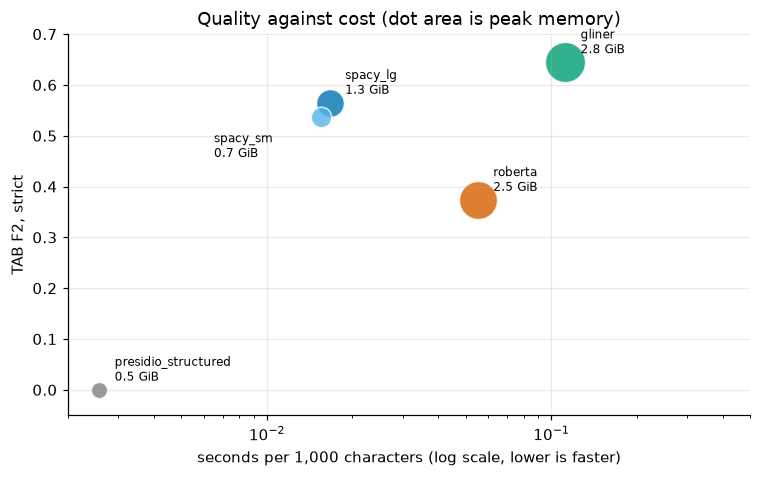

,TAB F2 (strict),"seconds per 1,000 chars",peak memory (GiB),load time (s)
spacy_lg,0.564,0.017,1.33,1.0
spacy_sm,0.536,0.015,0.72,0.7
roberta,0.373,0.055,2.49,1.8
gliner,0.644,0.112,2.78,6.0
presidio_structured,0.000,0.003,0.45,2.3


In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for tool in TOOLS:
    f2 = report(runs_off, tool, "tab").overall_micro.f2
    seconds = costs[tool]["latency_per_1000_chars_median_seconds"]
    memory = costs[tool]["peak_memory_bytes"] / 2**30
    ax.scatter(seconds, f2, s=memory * 250, color=TOOL_COLORS[tool], alpha=0.8, edgecolor="white")
    ax.annotate(f"{tool}\n{memory:.1f} GiB", (seconds, f2), textcoords="offset points",
                xytext=(-70, -26) if tool == "spacy_sm" else (10, 6), fontsize=8)
ax.set_xscale("log")
ax.set_xlim(0.002, 0.5)
ax.set_ylim(-0.05, 0.7)
ax.set_xlabel("seconds per 1,000 characters (log scale, lower is faster)")
ax.set_ylabel("TAB F2, strict")
ax.set_title("Quality against cost (dot area is peak memory)")
plt.show()

pd.DataFrame(
    {
        tool: {
            "TAB F2 (strict)": round(report(runs_off, tool, "tab").overall_micro.f2, 3),
            "seconds per 1,000 chars": round(costs[tool]["latency_per_1000_chars_median_seconds"], 3),
            "peak memory (GiB)": round(costs[tool]["peak_memory_bytes"] / 2**30, 2),
            "load time (s)": round(costs[tool]["load_seconds"], 1),
        }
        for tool in TOOLS
    }
).T

## 2b. Structured PII: how well Presidio finds IDs, bank numbers and contact details

The tables above score names, places and dates, where models do the work. Numbers with a fixed shape (cards, IBANs, phone numbers, IP addresses) are where Presidio's pattern rules are meant to shine, so this part measures them on their own, one kind at a time.

**The data.** There is no public real-world data with these labels, because real cards and IDs cannot be shared. So this uses two public **synthetic** datasets from Hugging Face, both on their test split: [`nvidia/Nemotron-PII`](https://huggingface.co/datasets/nvidia/Nemotron-PII) (100,000 English documents, US and international) and [`gretelai/synthetic_pii_finance_multilingual`](https://huggingface.co/datasets/gretelai/synthetic_pii_finance_multilingual) (5,594 financial documents in seven languages). Each labelled item is a stretch of text with a kind such as `iban` or `ssn`; only the kinds below are scored. A kind a dataset does not label simply has no row for that dataset.

**Presidio, all patterns on.** The toolkit's own `presidio_structured` setup switches on only 7 of Presidio's patterns (card, email, IBAN, IP address, URL, phone, US SSN), and its phone matcher looks at 8 regions. Here every predefined Presidio pattern is on (75 recognisers, for every country, with phone numbers read in all 245 regions) and run on every document whatever its language. No language model is involved. This evaluation is separate from the toolkit's, so the published results above are unchanged.

**Two rates per kind.** Both are detection rates (recall): the share of labelled items found.
- *Found as any PII*: the item overlaps a Presidio finding of any type.
- *Found as the correct kind*: it overlaps a finding whose type matches the kind (for example `IBAN_CODE` for an IBAN). A kind with no Presidio recogniser at all (SWIFT/BIC and BBAN) can only score on the first rate and always scores 0 on the second.

**Why checksums matter.** Card numbers, IBANs, US SSNs and US routing numbers carry built-in validity rules. Presidio uses them to throw out strings that only look like the right thing. Synthetic generators often produce numbers that fail those rules, which no real person would have. So each item is flagged valid or invalid, and rates are shown on all items and on validly-formed items only. Kinds without a checksum have the same number in both.

### The numbers, kind by kind

Rates are percentages of labelled items. `items` is how many items the dataset has for that kind; `valid items` is how many pass the checksum (equal to `items` for kinds without one). Rows starting `ALL` are the whole group.

In [11]:
import json

STRUCTURED = RESULTS / "structured"
STRUCTURED_DATASETS = {"nemotron": "Nemotron-PII", "gretel": "Gretel finance"}
structured = {name: json.loads((STRUCTURED / f"{name}__test.json").read_text()) for name in STRUCTURED_DATASETS}


def pct(value):
    return None if value is None else round(100 * value, 1)


structured_rows = []
for name, result in structured.items():
    for group, group_stats in result["overall"]["groups"].items():
        kinds = [(kind, stats) for kind, stats in result["overall"]["kinds"].items() if stats["group"] == group and stats["items"]]
        for label, stats in [*kinds, (f"ALL {group}", group_stats)]:
            structured_rows.append({
                "dataset": STRUCTURED_DATASETS[name],
                "group": group,
                "kind": label,
                "items": stats["items"],
                "valid items": stats["valid_items"],
                "any PII %, all": pct(stats["any_rate_all"]),
                "any PII %, valid": pct(stats["any_rate_valid"]),
                "correct kind %, all": pct(stats["correct_rate_all"]),
                "correct kind %, valid": pct(stats["correct_rate_valid"]),
            })
structured_table = pd.DataFrame(structured_rows).set_index(["dataset", "group", "kind"])
structured_table

items  valid items  any PII %, all  any PII %, valid  correct kind %, all  correct kind %, valid
dataset        group               kind                                                                                                                         
Nemotron-PII   Government IDs      ssn                           6062         6033           100.0             100.0                 99.5                  100.0
                                   tax_id                        1302         1302            97.8              97.8                 32.9                   32.9
                                   national_id                   2847         2847            92.1              92.1                 31.5                   31.5
                                   ALL Government IDs           10211        10182            97.5              97.5                 72.1                   72.3
               Financial           credit_debit_card            12867         1525            99.8             100.0                 11.8                   99.7
                                   account_number               16693        16693            97.6              97.6                 50.0                   50.0
                                   bank_routing_number           8354          843           100.0             100.0                 10.1                  100.0
                                   swift_bic                     5559         5559             6.4               6.4                  0.0                    0.0
                                   ALL Financial                43473        24620            87.0              77.2                 24.6                   43.5
               Travel and licences certificate_licence_number    3002         3002            98.2              98.2                 84.2                   84.2
                                   ALL Travel and licences       3002         3002            98.2              98.2                 84.2                   84.2
               Contact and network email                        53930        53930            99.6              99.6                 99.2                   99.2
                                   phone                        23930        23930            99.6              99.6                 99.4                   99.4
                                   fax                           6423         6423            99.4              99.4                 99.3                   99.3
                                   url                          37847        37847           100.0             100.0                 92.2                   92.2
                                   ipv4                          6078         6078           100.0             100.0                100.0                  100.0
                                   ipv6                          3139         3139            95.6              95.6                 90.9                   90.9
                                   mac_address                   4250         4250           100.0             100.0                100.0                  100.0
                                   ALL Contact and network     135597       135597            99.6              99.6                 97.2                   97.2
Gretel finance Government IDs      ssn                            153           76            98.7             100.0                 61.4                  100.0
                                   ALL Government IDs             153           76            98.7             100.0                 61.4                  100.0
               Financial           credit_debit_card              120           56            97.5             100.0                 37.5                   80.4
                                   bank_routing_number            158           14            93.7             100.0                  3.8                   42.9
                                   iban

### The same, as a chart

Light bars use all items; dark bars (checksum kinds only) use validly-formed items only.

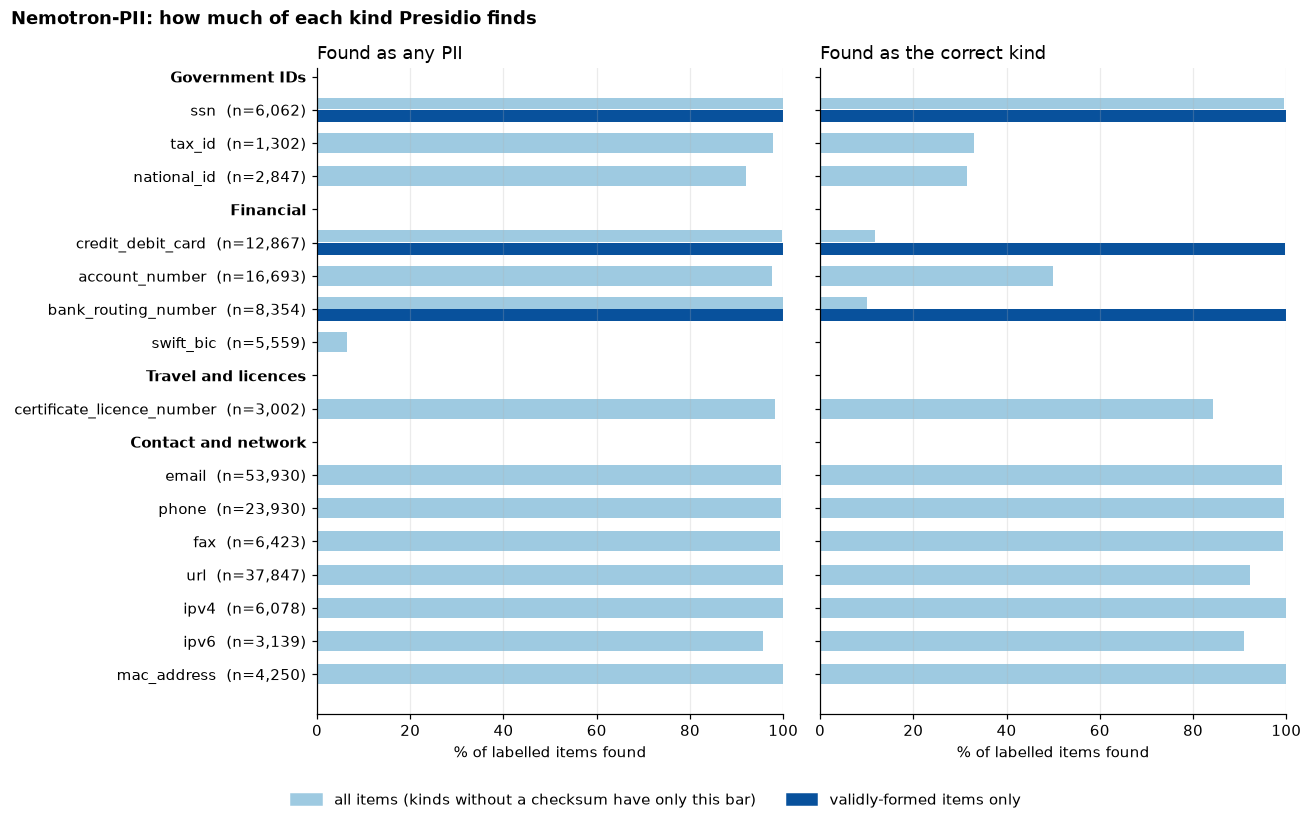

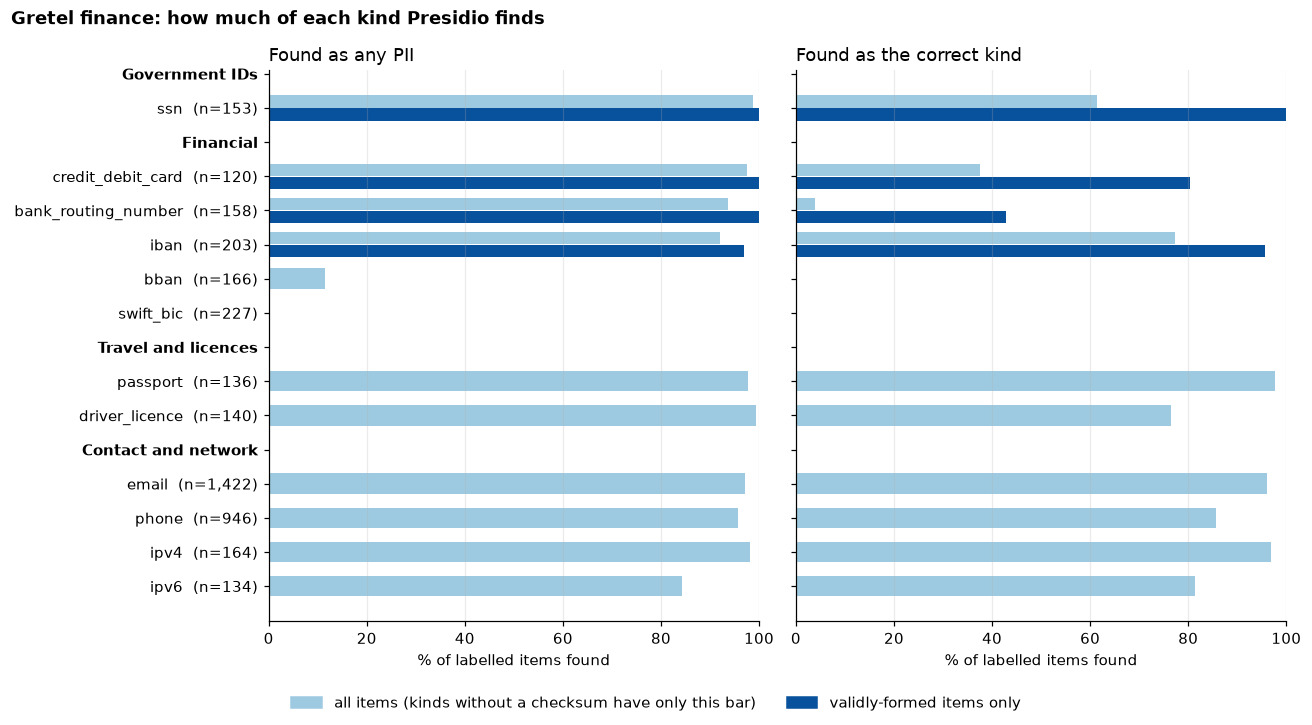

In [12]:
from matplotlib.patches import Patch

STRUCTURED_COLORS = {"all": "#9ecae1", "valid": "#08519c"}

for name, result in structured.items():
    kinds_stats = result["overall"]["kinds"]
    rows = []
    for group in result["overall"]["groups"]:
        group_kinds = [kind for kind, stats in kinds_stats.items() if stats["group"] == group and stats["items"]]
        if group_kinds:
            rows += [("header", group)] + [("kind", kind) for kind in group_kinds]

    fig, axes = plt.subplots(1, 2, figsize=(12, 0.3 * len(rows) + 1.8), sharey=True)
    for ax, (title, key) in zip(axes, [("Found as any PII", "any"), ("Found as the correct kind", "correct")]):
        for y, (role, label) in enumerate(rows):
            if role != "kind":
                continue
            stats = kinds_stats[label]
            if stats["has_checksum"]:
                ax.barh(y - 0.19, 100 * stats[f"{key}_rate_all"], height=0.36, color=STRUCTURED_COLORS["all"])
                ax.barh(y + 0.19, 100 * stats[f"{key}_rate_valid"], height=0.36, color=STRUCTURED_COLORS["valid"])
            else:
                ax.barh(y, 100 * stats[f"{key}_rate_all"], height=0.6, color=STRUCTURED_COLORS["all"])
        ax.set_xlim(0, 100)
        ax.set_xlabel("% of labelled items found")
        ax.set_title(title, loc="left")
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(range(len(rows)))
    axes[0].set_yticklabels([
        label if role == "header" else f"{label}  (n={kinds_stats[label]['items']:,})" for role, label in rows
    ])
    for tick, (role, _) in zip(axes[0].get_yticklabels(), rows):
        if role == "header":
            tick.set_fontweight("bold")
    axes[0].invert_yaxis()
    fig.legend(
        handles=[
            Patch(color=STRUCTURED_COLORS["all"], label="all items (kinds without a checksum have only this bar)"),
            Patch(color=STRUCTURED_COLORS["valid"], label="validly-formed items only"),
        ],
        loc="lower center", ncol=2, frameon=False,
    )
    fig.suptitle(f"{STRUCTURED_DATASETS[name]}: how much of each kind Presidio finds", x=0.01, ha="left", fontweight="bold")
    plt.tight_layout(rect=(0, 0.05, 1, 1))
    plt.show()


## 3. Your system, your data

Two cells below are marked **CHANGE THIS CELL**. Everything else reads from them and does not need editing.

1. **Your detector**: a function that takes text and returns the spans it found. The default wraps one of this toolbox's own detectors, so the notebook runs out of the box.
2. **Your data**: either a simple JSONL file, or one of this repository's datasets (so you can compare your system with the published numbers above).

Then the notebook scores your system with the same rules as part 2, next to a few of our detectors on the same documents.

In [13]:
# ===================== CHANGE THIS CELL: your detector =====================
# Replace the body of find_pii with a call to your own system. It receives one document's text and
# must return a list of (start, end, type) tuples: character offsets into the text (end is exclusive)
# and a type name. Return [] when nothing is found.
#
# Type names must be one of: PERSON, ORGANIZATION, LOCATION, DATE_TIME, QUANTITY, IDENTIFIER.
# If your system uses other names, list them in YOUR_TYPES_TO_OURS.

from pii_toolbox.core import Document
from pii_toolbox.detection.registry import build_from_config

YOUR_TYPES_TO_OURS = {}  # for example {"PER": "PERSON", "ORG": "ORGANIZATION", "GPE": "LOCATION"}

# The default is a small spaCy model plus the rules for emails, phone numbers and URLs.
# It runs offline, in a fraction of a second per page.
_default_detector = build_from_config(["spacy_sm+presidio_structured"])[0]
_default_detector.load_models()


def find_pii(text: str) -> list[tuple[int, int, str]]:
    document = Document("your-text", text, "en")
    return [(span.start, span.end, span.pii_type.value) for span in _default_detector.detect(document)]


SYSTEM_NAME = "your system"

W1027 16:47:20.207000 45597 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [14]:
# ===================== CHANGE THIS CELL: your data =====================
# DATA_SOURCE is "jsonl" for your own file, or "tab", "mapa" or "worldwide" for one of our datasets.
DATA_SOURCE = "jsonl"

# --- Your own file (used when DATA_SOURCE = "jsonl") ---
# One line per document, for example:
#   {"id": "a1", "text": "Call Maria on 555 0100.", "language": "en",
#    "spans": [{"start": 5, "end": 10, "type": "NAME"}, {"start": 14, "end": 22, "type": "PHONE"}]}
# "language" is optional (default "en"). "start" and "end" are character offsets, end exclusive.
JSONL_PATH = REPO / "notebooks" / "synthetic_examples.jsonl"
# Translates the type names in your file into ours. A type missing from this table stops the run
# with a message, so a typo cannot quietly drop answers.
YOUR_DATA_TYPES_TO_OURS = {
    "NAME": "PERSON",
    "ORG": "ORGANIZATION",
    "PLACE": "LOCATION",
    "DATE": "DATE_TIME",
    "MONEY": "QUANTITY",
    "EMAIL": "IDENTIFIER",
    "PHONE": "IDENTIFIER",
    "URL": "IDENTIFIER",
}

# --- One of our datasets (used when DATA_SOURCE is "tab", "mapa" or "worldwide") ---
# These need the datasets downloaded first: uv run python scripts/download_datasets.py
# Large documents take a while with the neural models, so keep MAX_DOCUMENTS small to start with.
DATASET_SPLIT = "test"
DATASET_LANGUAGE = None  # for example "fr" with MAPA; None means every language of the dataset
MAX_DOCUMENTS = 20

# --- Which of our detectors to compare against (names from the toolbox; "+" joins two) ---
REFERENCE_TOOLS = ["spacy_lg+presidio_structured", "roberta+presidio_structured", "gliner+presidio_structured"]

In [15]:
import json
import time
from itertools import islice

from pii_toolbox.core import AnswerSpan, Span, SpanMatchRule
from pii_toolbox.datasets.answer_key import AnyAnnotatorAnswerKeyBuilder
from pii_toolbox.evaluation.scorer import MatchingDetectionScorer


def load_jsonl_documents(path, type_map):
    documents = []
    for line_number, line in enumerate(Path(path).read_text().splitlines(), start=1):
        if not line.strip():
            continue
        raw = json.loads(line)
        document = Document(raw.get("id", f"line-{line_number}"), raw["text"], raw.get("language", "en"))
        answers = []
        for item in raw["spans"]:
            if item["type"] not in type_map:
                raise ValueError(
                    f"line {line_number}: type {item['type']!r} is not in YOUR_DATA_TYPES_TO_OURS; add it to the table"
                )
            pii_type = PiiType(type_map[item["type"]])
            answers.append(AnswerSpan(item["start"], item["end"], pii_type, item["type"], None, None, None))
        documents.append((document, answers))
    return documents


def load_dataset_documents(name, split, language, limit):
    from pii_toolbox.datasets.mapa import MapaDataset
    from pii_toolbox.datasets.tab import TabDataset
    from pii_toolbox.datasets.worldwide import WorldwideDataset

    dataset = {"tab": TabDataset, "mapa": MapaDataset, "worldwide": WorldwideDataset}[name]()
    key_builder = AnyAnnotatorAnswerKeyBuilder()
    annotated = islice(dataset.load(DatasetSplit[split.upper()], language), limit)
    return [(item.document, key_builder.build(item.answers)) for item in annotated]


if DATA_SOURCE == "jsonl":
    documents = load_jsonl_documents(JSONL_PATH, YOUR_DATA_TYPES_TO_OURS)
else:
    documents = load_dataset_documents(DATA_SOURCE, DATASET_SPLIT, DATASET_LANGUAGE, MAX_DOCUMENTS)

answer_counts = pd.Series([a.pii_type.value for _, answers in documents for a in answers if a.pii_type]).value_counts()
print(f"{len(documents)} documents, {sum(len(d.text) for d, _ in documents):,} characters, {answer_counts.sum()} answers")
answer_counts.rename("answers in your data").to_frame()

12 documents, 867 characters, 27 answers


,answers in your data
PERSON,7
LOCATION,5
IDENTIFIER,5
DATE_TIME,4
ORGANIZATION,4
QUANTITY,2


### Running your system and ours

Each system sees the same documents. A reference detector skips documents in a language it does not support (as in the published runs); your system sees everything. Time is the wall-clock time spent finding spans, excluding model loading.

In [16]:
def your_spans(text):
    spans = []
    for start, end, type_name in find_pii(text):
        pii_type = PiiType(YOUR_TYPES_TO_OURS.get(type_name, type_name))
        spans.append(Span(start, end, pii_type, type_name, (SYSTEM_NAME,), None))
    return spans


def run_system(name, find_spans, languages, detects):
    scored = []
    started = time.perf_counter()
    characters = 0
    for document, answers in documents:
        if languages is not None and document.language not in languages:
            continue
        scored.append((document, find_spans(document), answers))
        characters += len(document.text)
    seconds = time.perf_counter() - started
    return {"name": name, "scored": scored, "detects": detects, "seconds_per_1000_chars": seconds / max(characters, 1) * 1000}


systems = [run_system(SYSTEM_NAME, lambda d: your_spans(d.text), None, frozenset(PiiType))]
for tool in REFERENCE_TOOLS:
    detector = build_from_config([tool])[0]
    detector.load_models()
    systems.append(run_system(tool, detector.detect, detector.languages, detector.detects))

scorer = MatchingDetectionScorer()
SYSTEM_COLORS = {SYSTEM_NAME: "#CC79A7", **{tool: TOOL_COLORS[tool.split("+")[0]] for tool in REFERENCE_TOOLS}}


def system_report(system, strict):
    rule = SpanMatchRule.EXACT_BOUNDARIES if strict else SpanMatchRule.ANY_OVERLAP
    return scorer.score(system["scored"], rule, reported_types=system["detects"])


scores = {s["name"]: {"strict": system_report(s, True), "relaxed": system_report(s, False)} for s in systems}
skipped = {s["name"]: len(documents) - len(s["scored"]) for s in systems if len(s["scored"]) < len(documents)}
if skipped:
    print("Documents skipped because the language is not supported:", skipped)

### Overall scores

The same measures as part 2: precision, recall and F2, strict and relaxed. Here a flag of a kind your data never marks counts as a false alarm. In the table, `seconds per 1,000 chars` is comparable to the cost table above, though measured on your machine and your text. On a tiny sample the first calls of a neural model (warm-up) inflate it, so use a larger sample for a fair speed comparison.

In [17]:
rows = {}
for system in systems:
    name = system["name"]
    row = {}
    for rule in ("strict", "relaxed"):
        score = scores[name][rule].overall_micro
        row[f"precision ({rule})"] = score.precision
        row[f"recall ({rule})"] = score.recall
        row[f"F2 ({rule})"] = score.f2
    row["seconds per 1,000 chars"] = system["seconds_per_1000_chars"]
    rows[name] = row
overall = pd.DataFrame(rows).T.round(3)
overall

,precision (strict),recall (strict),F2 (strict),precision (relaxed),recall (relaxed),F2 (relaxed),"seconds per 1,000 chars"
your system,0.769,0.741,0.746,0.923,0.889,0.896,0.097
spacy_lg+presidio_structured,0.741,0.741,0.741,0.926,0.926,0.926,0.048
roberta+presidio_structured,0.818,0.667,0.692,0.955,0.778,0.808,0.365
gliner+presidio_structured,0.760,0.704,0.714,0.840,0.778,0.789,0.457


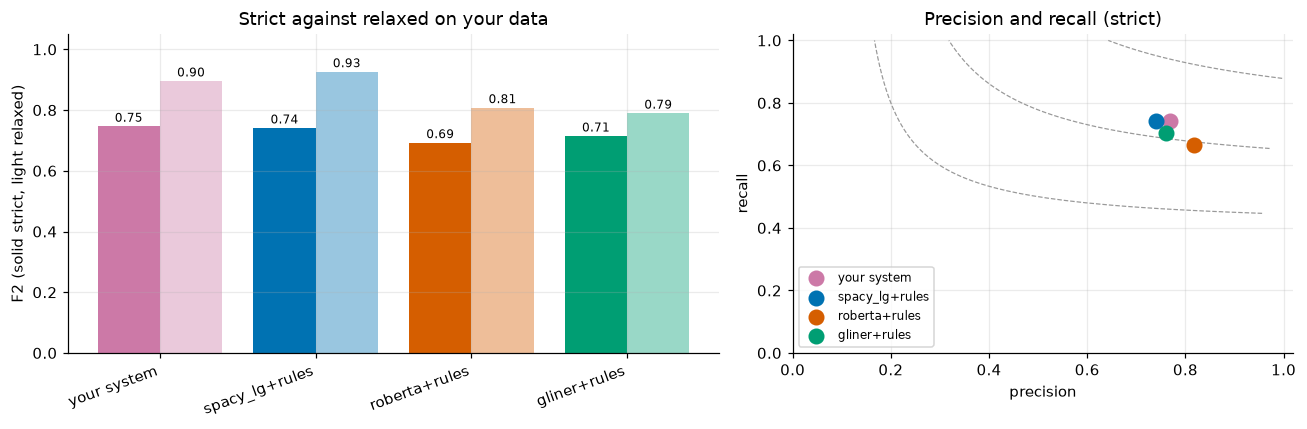

In [18]:
names = [s["name"] for s in systems]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.3, 1]})

ax = axes[0]
x = np.arange(len(names))
colors = [SYSTEM_COLORS[n] for n in names]
strict = [scores[n]["strict"].overall_micro.f2 for n in names]
relaxed = [scores[n]["relaxed"].overall_micro.f2 for n in names]
ax.bar(x - 0.2, strict, 0.4, color=colors, label="strict")
ax.bar(x + 0.2, relaxed, 0.4, color=colors, alpha=0.4, label="relaxed")
for xi, s, r in zip(x, strict, relaxed):
    ax.text(xi - 0.2, s + 0.015, f"{s:.2f}", ha="center", fontsize=8)
    ax.text(xi + 0.2, r + 0.015, f"{r:.2f}", ha="center", fontsize=8)
ax.set_xticks(x, [n.replace("+presidio_structured", "+rules") for n in names], rotation=20, ha="right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("F2 (solid strict, light relaxed)")
ax.set_title("Strict against relaxed on your data")

ax = axes[1]
for system in systems:
    score = scores[system["name"]]["strict"].overall_micro
    ax.scatter(score.precision, score.recall, s=90, color=SYSTEM_COLORS[system["name"]], zorder=3,
               label=system["name"].replace("+presidio_structured", "+rules"))
for level in (0.5, 0.7, 0.9):
    p, r = f2_curve(level)
    ax.plot(p, r, color="#999", lw=0.8, ls="--")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.set_xlabel("precision")
ax.set_ylabel("recall")
ax.set_title("Precision and recall (strict)")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

**How to read this.** If your system's recall is much lower than its precision, it is missing personal information; that is the dangerous direction and the one F2 punishes. If the relaxed bar is much taller than the strict one, it finds the right things but marks the wrong edges. With only a handful of documents the numbers move a lot from one run to the next, so treat the default synthetic file as a demonstration of the method, not as a verdict on any system.

### By kind of information

Strict F2 per kind, for every system. `n/a` means the system cannot report that kind, or your data has none of it.

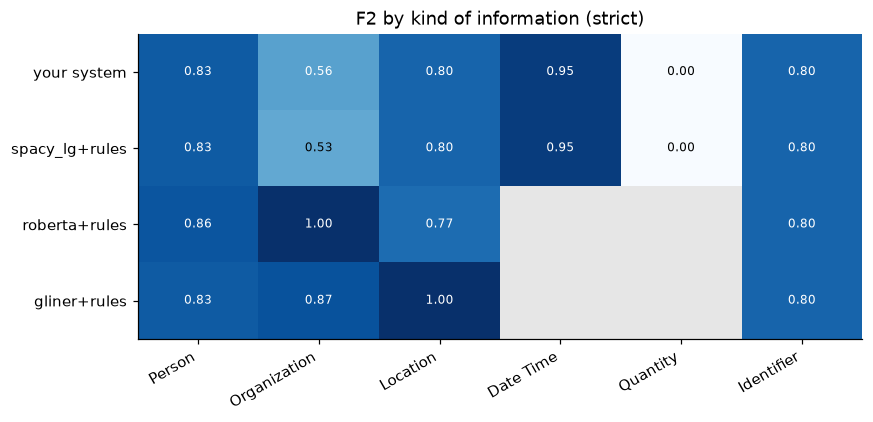

,Person,Organization,Location,Date Time,Quantity,Identifier
your system,0.833,0.556,0.8,0.952,0.0,0.8
spacy_lg+presidio_structured,0.833,0.526,0.8,0.952,0.0,0.8
roberta+presidio_structured,0.857,1.0,0.769,n/a,n/a,0.8
gliner+presidio_structured,0.833,0.87,1.0,n/a,n/a,0.8


In [19]:
by_type_rows = {}
for system in systems:
    by_type = scores[system["name"]]["strict"].by_type
    by_type_rows[system["name"]] = {
        TYPE_NAMES[t]: (by_type[t].f2 if by_type.get(t) is not None else np.nan) for t in TYPES
    }
by_type_table = pd.DataFrame(by_type_rows).T

fig, ax = plt.subplots(figsize=(8.5, 0.5 * len(systems) + 1.6))
grid = by_type_table.to_numpy(dtype=float)
ax.imshow(np.ma.masked_invalid(grid), vmin=0, vmax=1, cmap="Blues", aspect="auto")
ax.set_facecolor("#e6e6e6")
ax.grid(False)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        if not np.isnan(grid[i, j]):
            ax.text(j, i, f"{grid[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if grid[i, j] > 0.55 else "black")
ax.set_xticks(range(grid.shape[1]), by_type_table.columns, rotation=30, ha="right")
ax.set_yticks(range(grid.shape[0]), [n.replace("+presidio_structured", "+rules") for n in by_type_table.index])
ax.set_title("F2 by kind of information (strict)")
plt.show()
by_type_table.round(3).astype(object).where(by_type_table.notna(), "n/a")

### What your system gets wrong

A quick look at the individual mistakes, counting any overlap with an answer of the same kind, so that only complete misses and complete false alarms show up (edge problems are covered above). A **miss** is an answer that nothing of the right kind overlaps; a **false alarm** is a flag that overlaps no answer of the same kind.

In [20]:
MAX_EXAMPLES = 12


def overlaps(a_start, a_end, b_start, b_end):
    return a_start < b_end and b_start < a_end


def mistakes(system):
    missed, false_alarms = [], []
    for document, spans, answers in system["scored"]:
        for answer in answers:
            if answer.pii_type is None:
                continue
            found = any(
                s.pii_type is answer.pii_type and overlaps(s.start, s.end, answer.start, answer.end) for s in spans
            )
            if not found:
                missed.append((document.id, answer.pii_type.value, document.text[answer.start:answer.end]))
        for span in spans:
            matched = any(
                span.pii_type is a.pii_type and overlaps(span.start, span.end, a.start, a.end) for a in answers
            )
            if not matched:
                false_alarms.append((document.id, span.pii_type.value, document.text[span.start:span.end]))
    return missed, false_alarms


missed, false_alarms = mistakes(systems[0])
print(f"{SYSTEM_NAME}: {len(missed)} misses, {len(false_alarms)} false alarms")
pd.concat(
    {
        "missed (should have been flagged)": pd.DataFrame(missed[:MAX_EXAMPLES], columns=["document", "type", "text"]),
        "false alarm (should not have been flagged)": pd.DataFrame(
            false_alarms[:MAX_EXAMPLES], columns=["document", "type", "text"]
        ),
    },
    axis=1,
)

your system: 3 misses, 2 false alarms


missed (should have been flagged)                                  false alarm (should not have been flagged)                         
                           document          type               text                                   document       type          text
0                      synthetic-03  ORGANIZATION  Brightside Bakery                               synthetic-02  DATE_TIME        Friday
1                      synthetic-06  ORGANIZATION       Contoso Labs                               synthetic-06     PERSON  Contoso Labs
2                      synthetic-10      QUANTITY          EUR 1,200                                        NaN        NaN           NaN

### Try it on your own

- **Your detector:** edit the `find_pii` cell, for example to call a service or load a model, and re-run from that cell downwards.
- **Your file:** point `JSONL_PATH` at it and fill in `YOUR_DATA_TYPES_TO_OURS`.
- **Our datasets:** set `DATA_SOURCE` to `"tab"`, `"mapa"` or `"worldwide"` to score on the same text as the published numbers. Only a sample (`MAX_DOCUMENTS`) is scored here, so your numbers will differ from part 2, which covers the whole test split.